# GoSmart DS — Clinical Terms & Relational Ontology Knowledge Graph Playground

Interactive playground for exploring the ingested **OHDSI Athena Clinical Terminology Knowledge Graph** (`SNOMED`, `LOINC`, `ICD10CM`, `UCUM`) in Neo4j.

**What we demonstrate in this notebook:**
1. **Neo4j Connection & `CodeSystem` Registry** — canonical FHIR system URIs and release metadata
2. **Graph Inventory & Visual Breakdown** — concept status/standard distribution by vocabulary and ontology relationship counts
3. **Fast Concept Lookups** — exact `(vocabulary_id, code)` lookups and Lucene full-text + synonym search (`concept_fulltext_idx`)
4. **Cross-Terminology Mapping & Lifecycle** — `ICD10CM` → `SNOMED` via `[:MAPS_TO]` (with SKOS equivalence) and deprecated code resolution via `[:REPLACED_BY]`
5. **Ontology Hierarchy Traversal (`[:IS_A]`)** — ancestor lineage (`$subsumes`) and subtype ValueSet expansion with depth distribution chart
6. **Defining Clinical Attributes (`[:HAS_ATTRIBUTE]`)** — SNOMED CT clinical anatomy/morphology axes and LOINC Radiology Playbook imaging attributes
7. **Interactive Concept Card Helper** — one-line `inspect_concept(vocabulary_id, code)` inspector for ad-hoc exploration

## 1. Connect to Neo4j & Inspect Active `CodeSystem` Registry

Load GoSmart DS settings from `.env`, verify connectivity to the Neo4j instance, and inspect the ingested `:CodeSystem` nodes along with their canonical FHIR system URIs and concept counts.

In [12]:
from typing import Any, Optional

import matplotlib.pyplot as plt
import pandas as pd

from gosmart_dictionary_service.core.config import get_settings
from gosmart_dictionary_service.db.neo4j import Neo4jClient

pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 140)
pd.set_option("display.max_rows", 50)

settings = get_settings()
client = Neo4jClient(settings=settings)
driver = client.get_sync_driver()
driver.verify_connectivity()


def cypher_df(query: str, params: Optional[dict[str, Any]] = None) -> pd.DataFrame:
    """Execute a read-only Cypher query against Neo4j and return a pandas DataFrame."""
    with driver.session(database=settings.DB_DATABASE) as session:
        rows = [record.data() for record in session.run(query, params or {})]
    return pd.DataFrame(rows)


print(f"Connected to Neo4j: {settings.DB_CONNECTION_URI} (db={settings.DB_DATABASE})")

code_systems_df = cypher_df(
    """
    MATCH (cs:CodeSystem)
    WHERE cs.test_id IS NULL
    OPTIONAL MATCH (c:Concept)-[:BELONGS_TO_SYSTEM]->(cs)
    WHERE c.test_id IS NULL
    RETURN cs.vocabulary_id AS vocabulary_id,
           cs.name AS name,
           cs.system_uri AS system_uri,
           cs.version AS version,
           count(c) AS concept_count
    ORDER BY concept_count DESC
    """
)
display(code_systems_df)

Connected to Neo4j: bolt://manabusb3.local.:7688 (db=neo4j)


,vocabulary_id,name,system_uri,version,concept_count
0,SNOMED,Systematic Nomenclature of Medicine - Clinical Terms (IHTSDO),http://snomed.info/sct,2026-02-01 SNOMED CT International Edition; 2026-03-01 SNOMED CT US Edition; 2026-04-08 SNOMED C...,1106309
1,LOINC,Logical Observation Identifiers Names and Codes (Regenstrief Institute),http://loinc.org,LOINC 2.82,287814
2,ICD10CM,"International Classification of Diseases, Tenth Revision, Clinical Modification (NCHS)",http://hl7.org/fhir/sid/icd-10-cm,ICD10CM FY2027 code descriptions,100273
3,UCUM,Unified Code for Units of Measure (Regenstrief Institute),http://unitsofmeasure.org,Version 1.8.2,1130


## 2. Clinical Knowledge Graph Inventory & Visual Breakdown

Summarize concept status (`Standard`, `Classification`, `Non-standard`, and `Deprecated/Upgraded`) per vocabulary, top clinical domains, and ontology relationship counts across the production graph.

In [13]:
vocab_breakdown_df = cypher_df(
    """
    MATCH (c:Concept)
    WHERE c.test_id IS NULL
    RETURN c.vocabulary_id AS vocabulary_id,
           count(c) AS total_concepts,
           sum(CASE WHEN c.invalid_reason IS NULL AND c.standard_concept = 'S' THEN 1 ELSE 0 END) AS valid_standard,
           sum(CASE WHEN c.invalid_reason IS NULL AND c.standard_concept = 'C' THEN 1 ELSE 0 END) AS valid_classification,
           sum(CASE WHEN c.invalid_reason IS NULL AND c.standard_concept IS NULL THEN 1 ELSE 0 END) AS valid_non_standard,
           sum(CASE WHEN c.invalid_reason IS NOT NULL THEN 1 ELSE 0 END) AS deprecated_or_upgraded,
           sum(CASE WHEN size(coalesce(c.synonyms, [])) > 0 THEN 1 ELSE 0 END) AS concepts_with_synonyms
    ORDER BY total_concepts DESC
    """
)

domain_df = cypher_df(
    """
    MATCH (c:Concept)
    WHERE c.test_id IS NULL AND c.invalid_reason IS NULL
    RETURN c.domain_id AS domain_id,
           count(c) AS valid_concepts,
           sum(CASE WHEN c.standard_concept = 'S' THEN 1 ELSE 0 END) AS standard_concepts
    ORDER BY valid_concepts DESC
    LIMIT 12
    """
)

rel_counts_df = cypher_df(
    """
    CALL () {
        MATCH ()-[r:BELONGS_TO_SYSTEM]->() RETURN 'BELONGS_TO_SYSTEM' AS relationship_type, count(r) AS rel_count
        UNION ALL
        MATCH ()-[r:IS_A]->() RETURN 'IS_A' AS relationship_type, count(r) AS rel_count
        UNION ALL
        MATCH ()-[r:MAPS_TO]->() RETURN 'MAPS_TO' AS relationship_type, count(r) AS rel_count
        UNION ALL
        MATCH ()-[r:HAS_ATTRIBUTE]->() RETURN 'HAS_ATTRIBUTE' AS relationship_type, count(r) AS rel_count
        UNION ALL
        MATCH ()-[r:REPLACED_BY]->() RETURN 'REPLACED_BY' AS relationship_type, count(r) AS rel_count
    }
    RETURN relationship_type, rel_count
    ORDER BY rel_count DESC
    """
)

print(f"Total :Concept nodes       : {vocab_breakdown_df['total_concepts'].sum():,}")
print(f"Total valid :Concept nodes : {(vocab_breakdown_df['total_concepts'] - vocab_breakdown_df['deprecated_or_upgraded']).sum():,}")
print(f"Total clinical edges       : {rel_counts_df['rel_count'].sum():,}")
display(vocab_breakdown_df)
display(domain_df)
display(rel_counts_df)

Total :Concept nodes       : 1,495,526
Total valid :Concept nodes : 765,285
Total clinical edges       : 5,116,447


,vocabulary_id,total_concepts,valid_standard,valid_classification,valid_non_standard,deprecated_or_upgraded,concepts_with_synonyms
0,SNOMED,1106309,356613,0,65144,684552,619913
1,LOINC,287814,125586,49719,68779,43730,128144
2,ICD10CM,100273,0,0,98403,1870,56147
3,UCUM,1130,1041,0,0,89,4


,domain_id,valid_concepts,standard_concepts
0,Observation,214615,126809
1,Condition,202848,112693
2,Measurement,149913,98300
3,Procedure,61377,57676
4,Drug,41657,0
5,Spec Anatomic Site,38455,38455
6,Meas Value,27520,26126
7,Device,15365,15147
8,Note,4121,3644
9,Unit,2255,1041


,relationship_type,rel_count
0,HAS_ATTRIBUTE,1638228
1,BELONGS_TO_SYSTEM,1495526
2,IS_A,1463173
3,MAPS_TO,300946
4,REPLACED_BY,218574


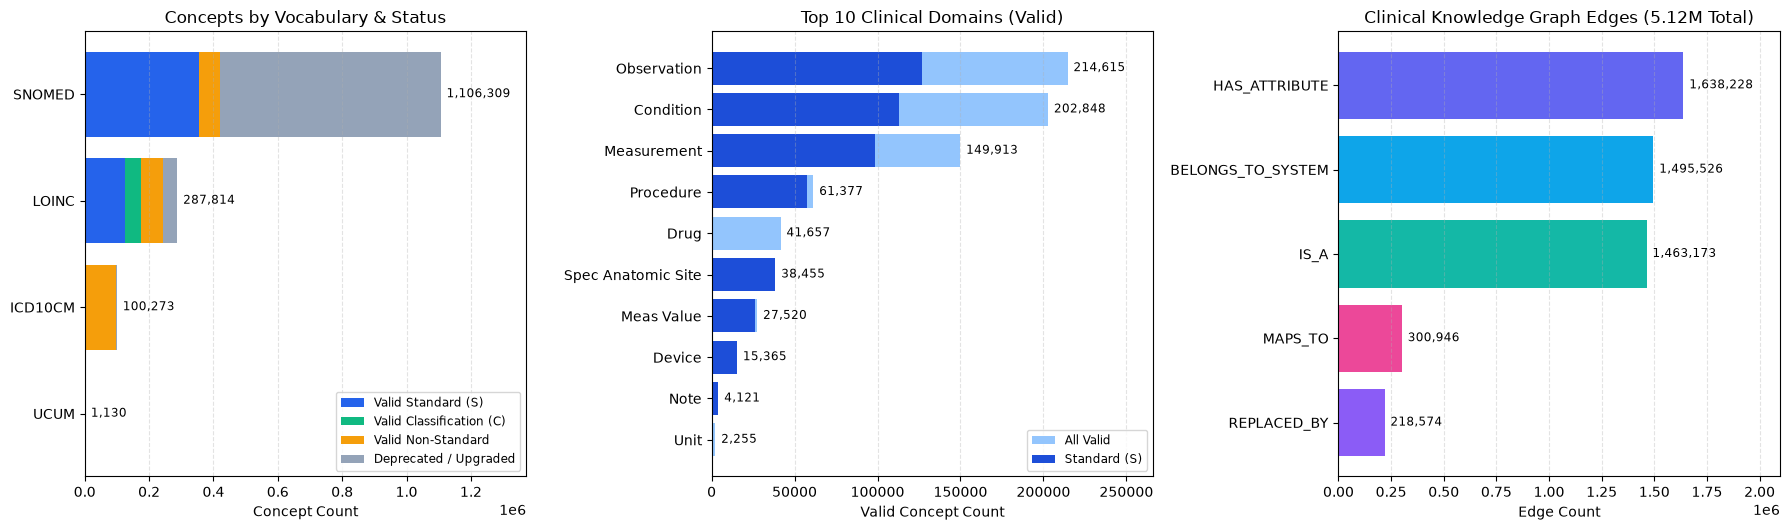

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.4))

# 1) Stacked horizontal bar: Concept Status by Vocabulary
vb = vocab_breakdown_df.sort_values("total_concepts", ascending=True)
y_v = range(len(vb))
p1 = axes[0].barh(y_v, vb["valid_standard"], label="Valid Standard (S)", color="#2563eb")
p2 = axes[0].barh(
    y_v,
    vb["valid_classification"],
    left=vb["valid_standard"],
    label="Valid Classification (C)",
    color="#10b981",
)
left_ns = vb["valid_standard"] + vb["valid_classification"]
p3 = axes[0].barh(
    y_v,
    vb["valid_non_standard"],
    left=left_ns,
    label="Valid Non-Standard",
    color="#f59e0b",
)
left_dep = left_ns + vb["valid_non_standard"]
p4 = axes[0].barh(
    y_v,
    vb["deprecated_or_upgraded"],
    left=left_dep,
    label="Deprecated / Upgraded",
    color="#94a3b8",
)
axes[0].set_yticks(list(y_v))
axes[0].set_yticklabels(vb["vocabulary_id"])
axes[0].set_xlabel("Concept Count")
axes[0].set_title("Concepts by Vocabulary & Status")
axes[0].legend(loc="lower right", fontsize=8.5, frameon=True)
axes[0].grid(axis="x", linestyle="--", alpha=0.35)
for idx, total in enumerate(vb["total_concepts"]):
    axes[0].text(total + 18000, idx, f"{total:,}", va="center", fontsize=8.5)
axes[0].set_xlim(right=vb["total_concepts"].max() * 1.24)

# 2) Horizontal bar: Top Clinical Domains (Valid Concepts)
dom = domain_df.head(10).sort_values("valid_concepts", ascending=True)
y_d = range(len(dom))
axes[1].barh(y_d, dom["valid_concepts"], label="All Valid", color="#93c5fd")
axes[1].barh(y_d, dom["standard_concepts"], label="Standard (S)", color="#1d4ed8")
axes[1].set_yticks(list(y_d))
axes[1].set_yticklabels(dom["domain_id"])
axes[1].set_xlabel("Valid Concept Count")
axes[1].set_title("Top 10 Clinical Domains (Valid)")
axes[1].legend(loc="lower right", fontsize=8.5, frameon=True)
axes[1].grid(axis="x", linestyle="--", alpha=0.35)
for idx, cnt in enumerate(dom["valid_concepts"]):
    axes[1].text(cnt + 3500, idx, f"{cnt:,}", va="center", fontsize=8.5)
axes[1].set_xlim(right=dom["valid_concepts"].max() * 1.24)

# 3) Horizontal bar: Ontology Relationships by Type
rc = rel_counts_df.sort_values("rel_count", ascending=True)
rel_colors = ["#8b5cf6", "#ec4899", "#14b8a6", "#0ea5e9", "#6366f1"]
bars = axes[2].barh(rc["relationship_type"], rc["rel_count"], color=rel_colors[: len(rc)])
axes[2].set_xlabel("Edge Count")
axes[2].set_title("Clinical Knowledge Graph Edges (5.12M Total)")
axes[2].grid(axis="x", linestyle="--", alpha=0.35)
for bar, cnt in zip(bars, rc["rel_count"]):
    axes[2].text(cnt + 28000, bar.get_y() + bar.get_height() / 2, f"{cnt:,}", va="center", fontsize=8.5)
axes[2].set_xlim(right=rc["rel_count"].max() * 1.28)

plt.tight_layout()
plt.show()

## 3. Fast Concept Lookups (Exact Code & Lucene Full-Text + Synonym Search)

Demonstrate two primary lookup patterns supported natively by the Neo4j indexes in `clinical_schema.cypher`:
- **Exact `(vocabulary_id, code)` lookup** using the composite index `concept_vocab_code_idx`
- **Lexical + Synonym search** using the Lucene full-text index `concept_fulltext_idx` across `Concept.display`, `Concept.code`, and `Concept.synonyms` (for example, searching `"heart attack"` matches SNOMED's *Myocardial infarction* via its attached synonyms).

In [15]:
import time


def lookup_concept(vocabulary_id: str, code: str) -> pd.DataFrame:
    """Exact indexed lookup by (vocabulary_id, code)."""
    return cypher_df(
        """
        MATCH (c:Concept {vocabulary_id: $vocab, code: $code})-[:BELONGS_TO_SYSTEM]->(cs:CodeSystem)
        WHERE c.test_id IS NULL
        RETURN c.vocabulary_id AS vocabulary_id,
               c.code AS code,
               c.display AS display,
               c.domain_id AS domain_id,
               c.concept_class_id AS concept_class_id,
               c.standard_concept AS standard,
               c.invalid_reason AS invalid_reason,
               cs.system_uri AS system_uri,
               c.synonyms[0..4] AS sample_synonyms
        """,
        {"vocab": vocabulary_id, "code": code},
    )


def search_concepts(
    query: str,
    *,
    vocabulary_id: Optional[str] = None,
    domain_id: Optional[str] = None,
    valid_only: bool = True,
    standard_only: bool = False,
    limit: int = 8,
) -> pd.DataFrame:
    """Search Concept.display, Concept.code, and Concept.synonyms via concept_fulltext_idx."""
    return cypher_df(
        """
        CALL db.index.fulltext.queryNodes('concept_fulltext_idx', $query)
        YIELD node AS c, score
        WHERE c.test_id IS NULL
          AND ($vocab IS NULL OR c.vocabulary_id = $vocab)
          AND ($domain IS NULL OR c.domain_id = $domain)
          AND (NOT $valid_only OR c.invalid_reason IS NULL)
          AND (NOT $standard_only OR c.standard_concept = 'S')
        RETURN round(score, 3) AS lucene_score,
               c.vocabulary_id AS vocabulary_id,
               c.code AS code,
               c.display AS display,
               c.domain_id AS domain_id,
               c.concept_class_id AS concept_class_id,
               c.standard_concept AS standard,
               c.synonyms[0..3] AS sample_synonyms
        ORDER BY lucene_score DESC
        LIMIT $limit
        """,
        {
            "query": query,
            "vocab": vocabulary_id,
            "domain": domain_id,
            "valid_only": valid_only,
            "standard_only": standard_only,
            "limit": limit,
        },
    )


# 1) Exact code lookups across all 4 CodeSystems
t0 = time.perf_counter()
exact_samples = pd.concat(
    [
        lookup_concept("ICD10CM", "E11.9"),
        lookup_concept("SNOMED", "22298006"),
        lookup_concept("LOINC", "87279-6"),
        lookup_concept("UCUM", "mg/dL"),
    ],
    ignore_index=True,
)
elapsed_ms = (time.perf_counter() - t0) * 1000
print(f"4 exact indexed lookups completed in {elapsed_ms:.1f} ms:")
display(exact_samples)

# 2) Synonym-aware Lucene full-text lookups
for label, kwargs in [
    ("Synonym hit — 'heart attack' (SNOMED Standard Conditions)", dict(query='"heart attack"', vocabulary_id="SNOMED", domain_id="Condition", standard_only=True, limit=6)),
    ("Radiology Playbook — 'CT Chest' (LOINC valid concepts)", dict(query='+"CT" +"Chest"', vocabulary_id="LOINC", valid_only=True, limit=8)),
    ("Cross-vocabulary — 'pulmonary embolism' (valid concepts)", dict(query='"pulmonary embolism"', valid_only=True, limit=8)),
]:
    t0 = time.perf_counter()
    res = search_concepts(**kwargs)
    ms = (time.perf_counter() - t0) * 1000
    print()
    print(f"=== {label} ({ms:.1f} ms) ===")
    display(res)

4 exact indexed lookups completed in 109.7 ms:


,vocabulary_id,code,display,domain_id,concept_class_id,standard,invalid_reason,system_uri,sample_synonyms
0,ICD10CM,E11.9,Type 2 diabetes mellitus without complications,Condition,4-char billing code,None,None,http://hl7.org/fhir/sid/icd-10-cm,[]
1,SNOMED,22298006,Myocardial infarction,Condition,Disorder,S,None,http://snomed.info/sct,"[Cardiac infarct (SNOMED Veterinary), Cardiac infarction, Heart attack, Myocardial infarct]"
2,LOINC,87279-6,CT Chest for screening,Procedure,Clinical Observation,S,None,http://loinc.org,[Asympt; Asymptomatic; CAT scan; Computed tomography; Computerized tomography; CT scan; Document...
3,UCUM,mg/dL,milligram per deciliter,Unit,Unit,S,None,http://unitsofmeasure.org,[]


Received notification from DBMS server: <GqlStatusObject gql_status='01N01', status_description='warn: feature deprecated with replacement. db.index.fulltext.queryNodes is deprecated. It is replaced by SEARCH.', position=<SummaryInputPosition line=2, column=9, offset=9>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 9, 'line': 2, 'column': 9}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "\n        CALL db.index.fulltext.queryNodes('concept_fulltext_idx', $query)\n        YIELD node AS c, score\n        WHERE c.test_id IS NULL\n          AND ($vocab IS NULL OR c.vocabulary_id = $vocab)\n          AND ($domain IS NULL OR c.domain_id = $domain)\n          AND (NOT $valid_only OR c.invalid_reason IS NULL)\n          AND (NOT $


=== Synonym hit — 'heart attack' (SNOMED Standard Conditions) (19.9 ms) ===


,lucene_score,vocabulary_id,code,display,domain_id,concept_class_id,standard,sample_synonyms
0,15.244,SNOMED,247818001,Fear of having a heart attack,Condition,Clinical Finding,S,[Fear of having a heart attack (finding)]
1,5.066,SNOMED,22298006,Myocardial infarction,Condition,Disorder,S,"[Cardiac infarct (SNOMED Veterinary), Cardiac infarction, Heart attack]"


Received notification from DBMS server: <GqlStatusObject gql_status='01N01', status_description='warn: feature deprecated with replacement. db.index.fulltext.queryNodes is deprecated. It is replaced by SEARCH.', position=<SummaryInputPosition line=2, column=9, offset=9>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 9, 'line': 2, 'column': 9}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "\n        CALL db.index.fulltext.queryNodes('concept_fulltext_idx', $query)\n        YIELD node AS c, score\n        WHERE c.test_id IS NULL\n          AND ($vocab IS NULL OR c.vocabulary_id = $vocab)\n          AND ($domain IS NULL OR c.domain_id = $domain)\n          AND (NOT $valid_only OR c.invalid_reason IS NULL)\n          AND (NOT $


=== Radiology Playbook — 'CT Chest' (LOINC valid concepts) (31.2 ms) ===


,lucene_score,vocabulary_id,code,display,domain_id,concept_class_id,standard,sample_synonyms
0,13.083,LOINC,103874-4,CT Chest and Abdomen,Procedure,Clinical Observation,S,[Abd; Abdo; Abdomen+; Abdominal; CAT scan; Chest + Abd; Computed tomography; Computerized tomogr...
1,12.794,LOINC,36089-1,CT Chest limited,Procedure,Clinical Observation,S,[CAT scan; Computed tomography; Computerized tomography; CT scan; Document; Finding; Findings; I...
2,12.782,LOINC,62617-6,PhenX - respiratory - chest computed tomography - CT protocol 090401,Measurement,Clinical Observation,S,"[Resp chest CT proto, Pan; Panel; PANEL.PHENX; Panl; Pnl; Point in time; Random; Resp chest CT p..."
3,12.372,LOINC,87869-4,CT Chest and Abdomen and Pelvis,Procedure,Clinical Observation,S,[Abd; Abd+Pelvis; Abdo; Abdominal; CAT scan; Chest + Abd; Chest+Abd+Pelvis; Computed tomography;...
4,12.256,LOINC,87279-6,CT Chest for screening,Procedure,Clinical Observation,S,[Asympt; Asymptomatic; CAT scan; Computed tomography; Computerized tomography; CT scan; Document...
5,11.978,LOINC,99628-0,CT Neck+Chest+Abdomen+Pelvis,Procedure,Clinical Observation,S,[Abd; Abd+Pelvis; Abdo; Abdominal; CAT scan; Chest + Abd; Chest+Abd+Pelvis; Computed tomography;...
6,11.918,LOINC,87863-7,CT Abdomen WO and CT Chest and Abdomen W contrast IV,Procedure,Clinical Observation,S,[Abd; Abd and Chest+Abd; Abdo; Abdomen+; Abdominal; c; CAT scan; Chest + Abd; Computed tomograph...
7,11.769,LOINC,29252-4,CT Chest WO contrast,Procedure,Clinical Observation,S,[c; CAT scan; Computed tomography; Computerized tomography; Contr; Contra; Contrst; CorePlaybook...


Received notification from DBMS server: <GqlStatusObject gql_status='01N01', status_description='warn: feature deprecated with replacement. db.index.fulltext.queryNodes is deprecated. It is replaced by SEARCH.', position=<SummaryInputPosition line=2, column=9, offset=9>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 9, 'line': 2, 'column': 9}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "\n        CALL db.index.fulltext.queryNodes('concept_fulltext_idx', $query)\n        YIELD node AS c, score\n        WHERE c.test_id IS NULL\n          AND ($vocab IS NULL OR c.vocabulary_id = $vocab)\n          AND ($domain IS NULL OR c.domain_id = $domain)\n          AND (NOT $valid_only OR c.invalid_reason IS NULL)\n          AND (NOT $


=== Cross-vocabulary — 'pulmonary embolism' (valid concepts) (24.7 ms) ===


,lucene_score,vocabulary_id,code,display,domain_id,concept_class_id,standard,sample_synonyms
0,18.231,SNOMED,59282003,Pulmonary embolism,Condition,Disorder,S,"[Pulmonary embolism (disorder), PE - Pulmonary embolism]"
1,17.264,SNOMED,417113001,Pulmonary embolism suspected,Observation,Context-dependent,S,"[Pulmonary embolism suspected (situation), Suspected PE (pulmonary embolism)]"
2,16.872,SNOMED,200284000,Obstetric pulmonary embolism,Condition,Disorder,S,"[Obstetric pulmonary embolism (disorder), Puerperal pulmonary embolism, Obstetric pulmonary embo..."
3,16.684,SNOMED,233936003,Acute massive pulmonary embolism,Condition,Disorder,S,"[Acute massive pulmonary embolism (disorder), AMP - Acute massive pulmonary embolism, AMPE - Acu..."
4,16.433,SNOMED,133971000119108,Chronic pulmonary embolism,Condition,Disorder,S,[Chronic pulmonary embolism (disorder)]
5,16.433,SNOMED,438773007,Recurrent pulmonary embolism,Condition,Disorder,S,[Recurrent pulmonary embolism (disorder)]
6,16.433,SNOMED,706870000,Acute pulmonary embolism,Condition,Disorder,S,[Acute pulmonary embolism (disorder)]
7,16.395,SNOMED,82153002,Miscarriage with pulmonary embolism,Condition,Disorder,S,"[Spontaneous abortion with pulmonary embolism, Miscarriage with pulmonary embolism (disorder)]"


## 4. Cross-Terminology Mapping (`[:MAPS_TO]`) & Deprecated Code Lifecycle (`[:REPLACED_BY]`)

In FHIR / OMOP clinical pipelines, billing codes (such as `ICD10CM`) are mapped to standard clinical concepts (`SNOMED`) via `[:MAPS_TO]` (enriched with SKOS equivalence from `CONCEPT_RELATIONSHIP_METADATA.csv`), while retired or upgraded codes resolve forward via `[:REPLACED_BY]`.

In [16]:
icd10_codes = ["E11.9", "I21.9", "J18.9", "I26.99", "C34.90", "I10"]

maps_to_df = cypher_df(
    """
    UNWIND $codes AS src_code
    MATCH (src:Concept {vocabulary_id: 'ICD10CM', code: src_code})
          -[r:MAPS_TO]->(dst:Concept)
    WHERE src.test_id IS NULL AND dst.test_id IS NULL
    RETURN src.code AS icd10_code,
           src.display AS icd10_display,
           r.relationship_id AS rel_id,
           r.equivalence AS skos_equivalence,
           dst.vocabulary_id AS target_vocab,
           dst.code AS target_code,
           dst.display AS target_display,
           dst.domain_id AS target_domain,
           dst.standard_concept AS target_standard
    ORDER BY icd10_code, target_code
    """,
    {"codes": icd10_codes},
)
print("ICD-10-CM -> Standard Concept Mappings ([:MAPS_TO]):")
display(maps_to_df)

# Summarize SKOS equivalence distribution on MAPS_TO edges
skos_summary_df = cypher_df(
    """
    MATCH ()-[r:MAPS_TO]->()
    RETURN coalesce(r.equivalence, '(OMOP native)') AS skos_equivalence,
           r.relationship_id AS relationship_id,
           count(r) AS edge_count
    ORDER BY edge_count DESC
    LIMIT 10
    """
)
print()
print("Top [:MAPS_TO] Relationship & SKOS Equivalence Breakdown:")
display(skos_summary_df)

# Show deprecated concepts resolved forward via [:REPLACED_BY]
replaced_df = cypher_df(
    """
    MATCH (old:Concept)-[r:REPLACED_BY]->(active:Concept)
    WHERE old.test_id IS NULL AND active.test_id IS NULL
      AND old.vocabulary_id = 'SNOMED'
      AND old.domain_id = 'Condition'
      AND active.invalid_reason IS NULL
    RETURN old.vocabulary_id AS vocab,
           old.code AS retired_code,
           old.display AS retired_display,
           old.invalid_reason AS invalid_reason,
           r.relationship_id AS rel_id,
           active.code AS active_code,
           active.display AS active_display,
           active.standard_concept AS active_standard
    LIMIT 8
    """
)
print()
print("Sample Deprecated SNOMED Conditions Resolved via [:REPLACED_BY]:")
display(replaced_df)

ICD-10-CM -> Standard Concept Mappings ([:MAPS_TO]):


,icd10_code,icd10_display,rel_id,skos_equivalence,target_vocab,target_code,target_display,target_domain,target_standard
0,C34.90,Malignant neoplasm of unspecified part of unspecified bronchus or lung,Maps to,None,SNOMED,93986008,Primary malignant neoplasm of respiratory tract,Condition,S
1,E11.9,Type 2 diabetes mellitus without complications,Maps to,None,SNOMED,44054006,Type 2 diabetes mellitus,Condition,S
2,I10,Essential (primary) hypertension,Maps to,None,SNOMED,59621000,Essential hypertension,Condition,S
3,I21.9,"Acute myocardial infarction, unspecified",Maps to,None,SNOMED,57054005,Acute myocardial infarction,Condition,S
4,I26.99,Other pulmonary embolism without acute cor pulmonale,Maps to,None,SNOMED,59282003,Pulmonary embolism,Condition,S
5,J18.9,"Pneumonia, unspecified organism",Maps to,None,SNOMED,233604007,Pneumonia,Condition,S



Top [:MAPS_TO] Relationship & SKOS Equivalence Breakdown:


,skos_equivalence,relationship_id,edge_count
0,(OMOP native),Maps to,271502
1,exactMatch,Maps to,13302
2,broadMatch,Maps to,7575
3,(OMOP native),Maps to value,5173
4,exactMatch,Maps to value,2467
5,broadMatch,Maps to value,744
6,narrowMatch,Maps to,171
7,narrowMatch,Maps to value,12



Sample Deprecated SNOMED Conditions Resolved via [:REPLACED_BY]:


,vocab,retired_code,retired_display,invalid_reason,rel_id,active_code,active_display,active_standard
0,SNOMED,76358005,Stillbirth,D,Concept poss_eq to,276507005,Fetal death,S
1,SNOMED,76358005,Stillbirth,D,Concept poss_eq to,237364002,Stillbirth,S
2,SNOMED,674831000000108,Adverse reaction to vaccine or biological substance NOS,D,Concept poss_eq to,293104008,Vaccine adverse reaction,S
3,SNOMED,11030007,Small visual image,D,Concept poss_eq to,421801003,Micropsia,S
4,SNOMED,146962002,(Fetal movements felt) or (quickening),D,Concept poss_eq to,249039001,Quickening,S
5,SNOMED,146962002,(Fetal movements felt) or (quickening),D,Concept poss_eq to,268470003,Fetal movements felt,S
6,SNOMED,147034003,Length of gestation,D,Concept poss_eq to,57036006,Fetal gestational age,S
7,SNOMED,147034003,Length of gestation,D,Concept poss_eq to,366323009,Finding of length of gestation,S


## 5. Ontology Hierarchy Traversal (`[:IS_A]` — Subsumption & ValueSet Expansion)

Neo4j traverses multi-hop `[:IS_A]` hierarchies natively without needing a precomputed 9.9M-row closure table:
- **Upward traversal (`$subsumes`)**: trace a specific clinical diagnosis up its SNOMED CT ancestor chain
- **Downward traversal (`$expand`)**: expand a parent condition into all valid Standard subtypes across hierarchy depths 1–5.

In [17]:
# 1) Upward lineage from Acute myocardial infarction (SNOMED 57054005)
ancestors_df = cypher_df(
    """
    MATCH p = (c:Concept {vocabulary_id: 'SNOMED', code: '57054005'})-[:IS_A*1..6]->(anc:Concept)
    WHERE c.test_id IS NULL AND anc.test_id IS NULL AND anc.invalid_reason IS NULL
    WITH anc, min(length(p)) AS min_hops
    RETURN min_hops,
           anc.code AS snomed_code,
           anc.display AS ancestor_display,
           anc.concept_class_id AS concept_class
    ORDER BY min_hops, ancestor_display
    LIMIT 20
    """
)
print("Upward [:IS_A] Ancestors of Acute myocardial infarction (SNOMED 57054005):")
display(ancestors_df)

# 2) Direct subtypes of Pneumonia (SNOMED 233604007)
pneumonia_children_df = cypher_df(
    """
    MATCH (child:Concept)-[:IS_A]->(parent:Concept {vocabulary_id: 'SNOMED', code: '233604007'})
    WHERE child.test_id IS NULL AND parent.test_id IS NULL AND child.invalid_reason IS NULL
    RETURN child.code AS snomed_code,
           child.display AS subtype_display,
           child.standard_concept AS standard,
           child.synonyms[0..2] AS sample_synonyms
    ORDER BY subtype_display
    LIMIT 12
    """
)
print()
print("Sample Direct [:IS_A] Subtypes of Pneumonia (SNOMED 233604007):")
display(pneumonia_children_df)

# 3) Depth-by-depth subtype expansion across 3 flagship SNOMED conditions
flagship_roots = [
    ("73211009", "Diabetes mellitus"),
    ("233604007", "Pneumonia"),
    ("22298006", "Myocardial infarction"),
]

expansion_df = cypher_df(
    """
    UNWIND $roots AS root
    MATCH p = (desc:Concept)-[:IS_A*1..5]->(parent:Concept {vocabulary_id: 'SNOMED', code: root.code})
    WHERE desc.test_id IS NULL AND parent.test_id IS NULL AND desc.invalid_reason IS NULL
    WITH root.label AS condition, desc, min(length(p)) AS depth
    RETURN condition, depth, count(DISTINCT desc) AS subtype_count
    ORDER BY condition, depth
    """,
    {"roots": [{"code": c, "label": lbl} for c, lbl in flagship_roots]},
)

pivot_exp = expansion_df.pivot(index="depth", columns="condition", values="subtype_count").fillna(0).astype(int)
pivot_exp.loc["Total (depth 1..5)"] = pivot_exp.sum()
print()
print("Valid SNOMED Subtype Expansion Counts by Hop Depth:")
display(pivot_exp)

Upward [:IS_A] Ancestors of Acute myocardial infarction (SNOMED 57054005):


,min_hops,snomed_code,ancestor_display,concept_class
0,1,413439005,Acute ischemic heart disease,Disorder
1,1,22298006,Myocardial infarction,Disorder
2,2,127337006,Acute heart disease,Disorder
3,2,414545008,Ischemic heart disease,Disorder
4,2,251061000,Myocardial necrosis,Disorder
5,3,128487001,Acute disease of cardiovascular system,Disorder
6,3,56265001,Heart disease,Disorder
7,3,86175003,Injury of heart,Disorder
8,3,301122000,Myocardial lesion,Disorder
9,3,609410002,Necrosis of anatomical site,Disorder



Sample Direct [:IS_A] Subtypes of Pneumonia (SNOMED 233604007):


,snomed_code,subtype_display,standard,sample_synonyms
0,196112005,Abscess of lung with pneumonia,S,[Abscess of lung with pneumonia (disorder)]
1,422588002,Aspiration pneumonia,S,"[Aspiration pneumonia (disorder), Inhalation pneumonia]"
2,53084003,Bacterial pneumonia,S,[Bacterial pneumonia (disorder)]
3,407671000,Bilateral pneumonia,S,[Bilateral pneumonia (disorder)]
4,396285007,Bronchopneumonia,S,"[Bronchial pneumonia, Lobular pneumonia]"
5,471272001,Cavitary pneumonia,S,[Cavitary pneumonia (disorder)]
6,102361000119104,Chronic pneumonia,S,[Chronic pneumonia (disorder)]
7,385093006,Community acquired pneumonia,S,"[CAP - community acquired pneumonia, Community acquired pneumonia (disorder)]"
8,123591006,Confluent pneumonia,S,[Confluent pneumonia (disorder)]
9,78895009,Congenital pneumonia,S,[Congenital pneumonia (disorder)]



Valid SNOMED Subtype Expansion Counts by Hop Depth:


condition,Diabetes mellitus,Myocardial infarction,Pneumonia
depth,,,
1,16,15,31
2,44,42,75
3,38,43,79
4,9,28,20
5,16,6,2
Total (depth 1..5),123,134,207


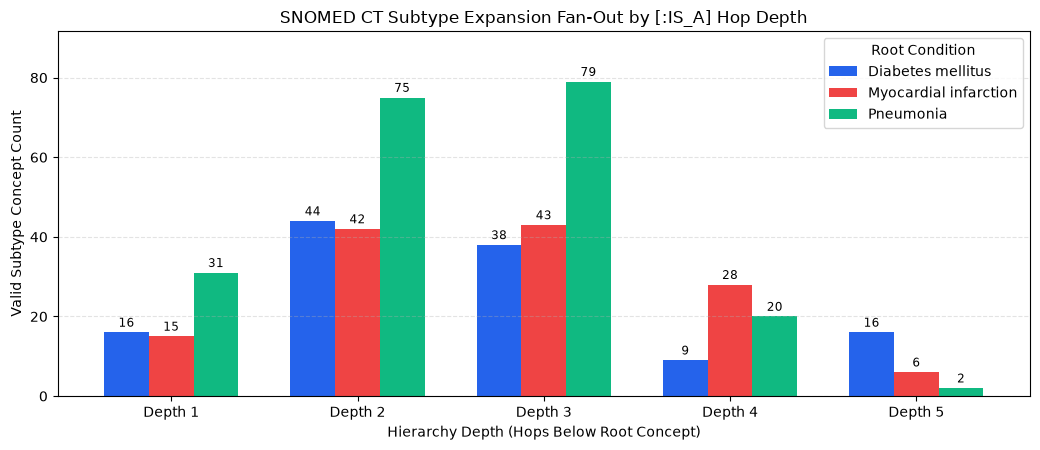

In [18]:
plot_df = pivot_exp.drop(index="Total (depth 1..5)")
ax = plot_df.plot(
    kind="bar",
    figsize=(10.5, 4.6),
    color=["#2563eb", "#ef4444", "#10b981"],
    width=0.72,
)
ax.set_title("SNOMED CT Subtype Expansion Fan-Out by [:IS_A] Hop Depth")
ax.set_xlabel("Hierarchy Depth (Hops Below Root Concept)")
ax.set_ylabel("Valid Subtype Concept Count")
ax.set_xticklabels([f"Depth {d}" for d in plot_df.index], rotation=0)
ax.legend(title="Root Condition", frameon=True)
ax.grid(axis="y", linestyle="--", alpha=0.35)

for container in ax.containers:
    ax.bar_label(container, padding=2, fontsize=8.5)

ax.set_ylim(top=plot_df.to_numpy().max() * 1.16)
plt.tight_layout()
plt.show()

## 6. Defining Clinical Attributes (`[:HAS_ATTRIBUTE]`) — Anatomy, Morphology & Radiology Axes

Beyond taxonomic `[:IS_A]` trees, `[:HAS_ATTRIBUTE]` stores **1.64M** canonical defining relationships (stored once per symmetric pair in canonical forward direction) capturing SNOMED CT clinical qualifiers (finding site, morphology, causative agent, procedure site) and LOINC / Radiology Playbook multi-axial properties (component, system, method, scale, modality).

In [19]:
# 1) Top [:HAS_ATTRIBUTE] predicates across the graph
top_attr_predicates_df = cypher_df(
    """
    MATCH ()-[r:HAS_ATTRIBUTE]->()
    RETURN r.relationship_id AS relationship_id, count(r) AS edge_count
    ORDER BY edge_count DESC
    LIMIT 12
    """
)
print("Top 12 [:HAS_ATTRIBUTE] Predicates in the Clinical Ontology:")
display(top_attr_predicates_df)

# 2) Defining clinical attributes for SNOMED Acute myocardial infarction (57054005)
#    (Check both directions since canonical forward direction can point from attribute -> concept or concept -> attribute)
snomed_attrs_df = cypher_df(
    """
    MATCH (c:Concept {vocabulary_id: 'SNOMED', code: '57054005'})-[r:HAS_ATTRIBUTE]-(other:Concept)
    WHERE c.test_id IS NULL AND other.test_id IS NULL AND other.invalid_reason IS NULL
    RETURN CASE WHEN startNode(r) = c THEN 'outgoing' ELSE 'incoming' END AS direction,
           r.relationship_id AS relationship_id,
           other.vocabulary_id AS target_vocab,
           other.code AS target_code,
           other.display AS target_display,
           other.domain_id AS target_domain
    ORDER BY direction, relationship_id, target_display
    LIMIT 20
    """
)
print()
print("Defining [:HAS_ATTRIBUTE] Relationships for Acute myocardial infarction (SNOMED 57054005):")
display(snomed_attrs_df)

# 3) LOINC Radiology Playbook defining axes for CT Chest for screening (LOINC 87279-6)
loinc_rad_attrs_df = cypher_df(
    """
    MATCH (c:Concept {vocabulary_id: 'LOINC', code: '87279-6'})-[r:HAS_ATTRIBUTE]-(other:Concept)
    WHERE c.test_id IS NULL AND other.test_id IS NULL AND other.invalid_reason IS NULL
    RETURN CASE WHEN startNode(r) = c THEN 'outgoing' ELSE 'incoming' END AS direction,
           r.relationship_id AS relationship_id,
           other.vocabulary_id AS target_vocab,
           other.code AS target_code,
           other.display AS target_display,
           other.concept_class_id AS target_class
    ORDER BY direction, relationship_id, target_display
    LIMIT 20
    """
)
print()
print("LOINC Radiology Playbook [:HAS_ATTRIBUTE] Axes for CT Chest for screening (LOINC 87279-6):")
display(loinc_rad_attrs_df)

Top 12 [:HAS_ATTRIBUTE] Predicates in the Clinical Ontology:


,relationship_id,edge_count
0,Has method,143014
1,Has finding site,126458
2,Has component,118416
3,Has Answer,114448
4,Has property,109948
5,Has scale type,104832
6,Has time aspect,104406
7,Has system,103225
8,Has asso morph,102035
9,Panel contains,55326



Defining [:HAS_ATTRIBUTE] Relationships for Acute myocardial infarction (SNOMED 57054005):


,direction,relationship_id,target_vocab,target_code,target_display,target_domain
0,incoming,Followed by,SNOMED,723860000,Arrhythmia due to and following acute myocardial infarction,Condition
1,incoming,Followed by,SNOMED,194863005,Atrial septal defect due to and following acute myocardial infarction,Condition
2,incoming,Followed by,SNOMED,233847009,Cardiac rupture due to and following acute myocardial infarction,Condition
3,incoming,Followed by,SNOMED,194862000,Hemopericardium due to and following acute myocardial infarction,Condition
4,incoming,Followed by,SNOMED,15960981000119105,Mural thrombus of left ventricle following acute myocardial infarction,Condition
5,incoming,Followed by,SNOMED,736978009,Mural thrombus of right ventricle following acute myocardial infarction,Condition
6,incoming,Followed by,SNOMED,723859005,Pulmonary embolism due to and following acute myocardial infarction,Condition
7,incoming,Followed by,SNOMED,194865003,Rupture of cardiac wall without hemopericardium as current complication following acute myocardi...,Condition
8,incoming,Followed by,SNOMED,194866002,Rupture of chordae tendinae due to and following acute myocardial infarction,Condition
9,incoming,Followed by,SNOMED,16528621000119102,Rupture of interventricular septum following acute myocardial infarction,Condition



LOINC Radiology Playbook [:HAS_ATTRIBUTE] Axes for CT Chest for screening (LOINC 87279-6):


,direction,relationship_id,target_vocab,target_code,target_display,target_class
0,outgoing,Has component,LOINC,LP200186-7,Multisection for screening,LOINC Component
1,outgoing,Has method,LOINC,LP6207-7,Computed tomography,LOINC Method
2,outgoing,Has property,LOINC,LP6813-2,Finding,LOINC Property
3,outgoing,Has scale type,LOINC,LP32888-7,Doc,LOINC Scale
4,outgoing,Has system,LOINC,LP7138-3,Chest,LOINC System
5,outgoing,Has time aspect,LOINC,LP6960-1,Point in time (spot),LOINC Time


## 7. Interactive Concept Card Inspector (`inspect_concept`)

Use `inspect_concept(vocabulary_id, code)` to interactively explore any `SNOMED`, `LOINC`, `ICD10CM`, or `UCUM` code—showing its FHIR URI, synonyms, parents, subtype count, cross-system mappings, and defining attributes in a single call.

In [20]:
def inspect_concept(vocabulary_id: str, code: str, *, max_rows: int = 10) -> None:
    """Print a structured Concept Card for any (vocabulary_id, code) in Neo4j."""
    core = cypher_df(
        """
        MATCH (c:Concept {vocabulary_id: $vocab, code: $code})-[:BELONGS_TO_SYSTEM]->(cs:CodeSystem)
        WHERE c.test_id IS NULL
        RETURN c.vocabulary_id AS vocabulary_id,
               c.code AS code,
               c.display AS display,
               cs.system_uri AS system_uri,
               c.domain_id AS domain_id,
               c.concept_class_id AS concept_class_id,
               c.standard_concept AS standard_concept,
               c.invalid_reason AS invalid_reason,
               c.athena_concept_id AS athena_concept_id,
               c.synonyms AS synonyms
        """,
        {"vocab": vocabulary_id, "code": code},
    )
    if core.empty:
        print(f"No concept found for ({vocabulary_id!r}, {code!r}).")
        return

    row = core.iloc[0]
    print(f"=== [{row['vocabulary_id']}] {row['code']} — {row['display']} ===")
    print(
        f"FHIR System : {row['system_uri']} | Domain: {row['domain_id']} | "
        f"Class: {row['concept_class_id']} | Standard: {row['standard_concept']} | "
        f"Invalid: {row['invalid_reason']} | Athena ID: {row['athena_concept_id']}"
    )
    syns = row["synonyms"] or []
    print(f"Synonyms ({len(syns)}): {syns[:6]}")

    summary_rels = cypher_df(
        """
        MATCH (c:Concept {vocabulary_id: $vocab, code: $code})
        WHERE c.test_id IS NULL
        RETURN count { MATCH (c)-[:IS_A]->(p:Concept) WHERE p.test_id IS NULL } AS direct_parents,
               count { MATCH (ch:Concept)-[:IS_A]->(c) WHERE ch.test_id IS NULL AND ch.invalid_reason IS NULL } AS valid_direct_children,
               count { MATCH (c)-[:MAPS_TO]->(m:Concept) WHERE m.test_id IS NULL } AS outgoing_maps_to,
               count { MATCH (s:Concept)-[:MAPS_TO]->(c) WHERE s.test_id IS NULL } AS incoming_maps_to,
               count { MATCH (c)-[:HAS_ATTRIBUTE]->(a:Concept) WHERE a.test_id IS NULL } AS outgoing_attributes
        """,
        {"vocab": vocabulary_id, "code": code},
    )
    display(summary_rels)

    neighbors = cypher_df(
        """
        MATCH (c:Concept {vocabulary_id: $vocab, code: $code})-[r:IS_A|MAPS_TO|REPLACED_BY|HAS_ATTRIBUTE]->(dst:Concept)
        WHERE c.test_id IS NULL AND dst.test_id IS NULL
        RETURN type(r) AS edge_type,
               coalesce(r.relationship_id, type(r)) AS relationship_id,
               dst.vocabulary_id AS target_vocab,
               dst.code AS target_code,
               dst.display AS target_display,
               dst.domain_id AS target_domain
        ORDER BY edge_type, relationship_id, target_display
        LIMIT $limit
        """,
        {"vocab": vocabulary_id, "code": code, "limit": max_rows},
    )
    if not neighbors.empty:
        print(f"Outgoing Ontology Edges (up to {max_rows}):")
        display(neighbors)


# Try inspecting a SNOMED disorder and an ICD-10-CM billing code (edit to explore any code!)
inspect_concept("SNOMED", "233604007")
print()
inspect_concept("ICD10CM", "I21.9")

=== [SNOMED] 233604007 — Pneumonia ===
FHIR System : http://snomed.info/sct | Domain: Condition | Class: Disorder | Standard: S | Invalid: None | Athena ID: 255848
Synonyms (1): ['Pneumonia (disorder)']


,direct_parents,valid_direct_children,outgoing_maps_to,incoming_maps_to,outgoing_attributes
0,2,31,0,33,4


Outgoing Ontology Edges (up to 10):


,edge_type,relationship_id,target_vocab,target_code,target_display,target_domain
0,HAS_ATTRIBUTE,Asso with finding,SNOMED,109814008,Acute ulcerative gastroenteritis complicating pneumonia,Condition
1,HAS_ATTRIBUTE,Has asso morph,SNOMED,409774005,Inflammatory morphology,Observation
2,HAS_ATTRIBUTE,Has finding site,SNOMED,113255004,Structure of parenchyma of lung,Spec Anatomic Site
3,HAS_ATTRIBUTE,Has pathology,SNOMED,441862004,Infectious process,Observation
4,IS_A,IS_A,SNOMED,128601007,Infectious disease of lung,Condition
5,IS_A,IS_A,SNOMED,205237003,Pneumonitis,Condition



=== [ICD10CM] I21.9 — Acute myocardial infarction, unspecified ===
FHIR System : http://hl7.org/fhir/sid/icd-10-cm | Domain: Condition | Class: 4-char billing code | Standard: None | Invalid: None | Athena ID: 1326588
Synonyms (0): []


,direct_parents,valid_direct_children,outgoing_maps_to,incoming_maps_to,outgoing_attributes
0,1,0,1,0,0


Outgoing Ontology Edges (up to 10):


,edge_type,relationship_id,target_vocab,target_code,target_display,target_domain
0,IS_A,IS_A,ICD10CM,I21,Acute myocardial infarction,Condition
1,MAPS_TO,Maps to,SNOMED,57054005,Acute myocardial infarction,Condition


## 8. Unified `SearchService` Demo (`search(query)` + `StubNLUService`)

Test the production `SearchService` (`src/gosmart_dictionary_service/service/search_service.py`) across:
1. **Free-text clinical search** (`"acute pneumonia"` — Lucene + 1-hop `[:IS_A]` parent convergence + on-the-fly `embedding-v1` rerank)
2. **Relational code lookup** (`"Find something related to LOINC 87279-6"` — forward + reverse + 2-hop shared-axis aggregation)
3. **Cross-system crosswalk** (`"Map ICD10CM E11.9 to SNOMED"`)
4. **Unified / DICOM search** (`"slice thickness"` across `DicomElement` HNSW + Lucene, projected in MCP `compact` format)

In [21]:
from gosmart_dictionary_service.model.search import ResponseFormat, SearchEntityType
from gosmart_dictionary_service.service.search_service import SearchService

svc = SearchService(client=client)

# 1) Free-text clinical search with 1-hop [:IS_A] parent convergence + on-the-fly embedding-v1 rerank
pneu_resp = await svc.search(
    "acute pneumonia",
    entity_types=[SearchEntityType.CONCEPT],
    limit=6,
)
print(
    f"Query: {pneu_resp.query!r} | intent={pneu_resp.nlu.intent.value} | "
    f"{pneu_resp.duration_ms:.1f} ms | warnings={pneu_resp.warnings}"
)
display(
    pd.DataFrame(
        [
            {
                "score": h.score,
                "vec": round(h.vector_score, 4) if h.vector_score is not None else None,
                "lex": round(h.lexical_score, 2) if h.lexical_score is not None else None,
                "sources": [s.value for s in h.match_sources],
                "vocab": h.properties.get("vocabulary"),
                "code": h.coding.code,
                "display": h.coding.display,
                "domain": h.properties.get("domain"),
            }
            for h in pneu_resp.hits
        ]
    )
)

# 2) Related concepts for LOINC 87279-6 (forward + reverse + 2-hop shared-axis aggregation)
rel_resp = await svc.search("Find something related to LOINC 87279-6", related_limit=10)
print()
print(
    f"Query: {rel_resp.query!r} | intent={rel_resp.nlu.intent.value} | "
    f"seed={rel_resp.hits[0].coding.code} ({rel_resp.hits[0].coding.display}) | {rel_resp.duration_ms:.1f} ms"
)
display(
    pd.DataFrame(
        [
            {
                "direction": r.direction.value,
                "reason": r.relation_reason.value,
                "predicate": r.relationship_id,
                "vocab": r.properties.get("vocabulary"),
                "code": r.coding.code,
                "display": r.coding.display,
                "shared_axes": r.shared_axes,
            }
            for r in rel_resp.hits[0].related
        ]
    )
)

# 3) Crosswalk query + DICOM element search in MCP compact format
cw_resp = await svc.search("Map ICD10CM E11.9 to SNOMED")
print()
print(f"Crosswalk ({cw_resp.duration_ms:.1f} ms):", cw_resp.to_wire(ResponseFormat.COMPACT)["hits"])

dicom_resp = await svc.search(
    "slice thickness",
    entity_types=[SearchEntityType.DICOM_ELEMENT],
    limit=4,
)
print()
print(f"DICOM Search ({dicom_resp.duration_ms:.1f} ms, MCP compact):")
display(pd.DataFrame(dicom_resp.to_wire(ResponseFormat.COMPACT)["hits"]))

Received notification from DBMS server: <GqlStatusObject gql_status='01N01', status_description='warn: feature deprecated with replacement. db.index.fulltext.queryNodes is deprecated. It is replaced by SEARCH.', position=<SummaryInputPosition line=2, column=1, offset=1>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 1, 'line': 2, 'column': 1}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "\nCALL db.index.fulltext.queryNodes('concept_fulltext_idx', $lucene_query)\nYIELD node AS c, score\nWHERE (($test_id IS NULL AND c.test_id IS NULL) OR ($test_id IS NOT NULL AND c.test_id = $test_id))\n  AND ($vocabs IS NULL OR c.vocabulary_id IN $vocabs)\n  AND ($domains IS NULL OR c.domain_id IN $domains)\n  AND (NOT $valid_only OR c.inva

Query: 'acute pneumonia' | intent=search | 1613.5 ms | warnings=[]


,score,vec,lex,sources,vocab,code,display,domain
0,0.7941,0.8141,10.22,"[fulltext, hybrid, is_a_parent]",SNOMED,233604007,Pneumonia,Condition
1,0.7847,0.8141,16.03,"[fulltext, hybrid]",SNOMED,35031000119100,Acute aspiration pneumonia,Condition
2,0.7718,0.8104,15.35,"[fulltext, hybrid]",SNOMED,184431000119108,Acute pneumonia caused by coccidioidomycosis,Condition
3,0.7467,0.7903,14.54,"[fulltext, hybrid]",SNOMED,109814008,Acute ulcerative gastroenteritis complicating pneumonia,Condition
4,0.7148,0.7835,12.76,"[fulltext, hybrid]",SNOMED,441590008,Pneumonia caused by Severe acute respiratory syndrome coronavirus,Condition
5,0.6953,0.8059,10.62,"[fulltext, hybrid]",SNOMED,7063008,Gangrenous pneumonia,Condition



Query: 'Find something related to LOINC 87279-6' | intent=related_lookup | seed=87279-6 (CT Chest for screening) | 108.4 ms


,direction,reason,predicate,vocab,code,display,shared_axes
0,forward,is_a_parent,IS_A,LOINC,LP405112-6,Chest | Computed tomography | Radiology,[]
1,forward,is_a_parent,IS_A,LOINC,RAD,Radiology,[]
2,forward,is_a_parent,IS_A,LOINC,LG41847-1,Region imaged: Chest,[]
3,both,shared_attribute,shared_attributes(2),LOINC,79096-4,CT Chest 3D post processing WO contrast,"[Computed tomography, Chest]"
4,both,shared_attribute,shared_attributes(2),LOINC,79068-3,CT Chest for screening W contrast IV,"[Computed tomography, Chest]"
5,both,shared_attribute,shared_attributes(2),LOINC,79086-5,CT Chest for screening WO contrast,"[Computed tomography, Chest]"
6,both,shared_attribute,shared_attributes(2),LOINC,36089-1,CT Chest limited,"[Computed tomography, Chest]"
7,both,shared_attribute,shared_attributes(2),LOINC,69096-6,CT Chest limited W contrast IV,"[Computed tomography, Chest]"
8,both,shared_attribute,shared_attributes(2),LOINC,47366-0,CT Chest limited WO contrast,"[Computed tomography, Chest]"
9,both,shared_attribute,shared_attributes(2),LOINC,24628-0,CT Chest W contrast IV,"[Computed tomography, Chest]"


Received notification from DBMS server: <GqlStatusObject gql_status='01N01', status_description='warn: feature deprecated with replacement. db.index.fulltext.queryNodes is deprecated. It is replaced by SEARCH.', position=<SummaryInputPosition line=2, column=1, offset=1>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 1, 'line': 2, 'column': 1}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "\nCALL db.index.fulltext.queryNodes('dicom_element_fulltext_idx', $lucene_query)\nYIELD node AS e, score\nWHERE (($test_id IS NULL AND e.test_id IS NULL) OR ($test_id IS NOT NULL AND e.test_id = $test_id))\n  AND (NOT $valid_only OR coalesce(e.is_retired, false) = false)\nRETURN e.id AS id,\n       'DicomElement' AS entity_type,\n       e.


Crosswalk (249.0 ms): [{'entity_type': 'Concept', 'macro': 'http://hl7.org/fhir/sid/icd-10-cm|E11.9|Type 2 diabetes mellitus without complications', 'vocab': 'ICD10CM', 'domain': 'Condition', 'score': 1.0, 'related': [{'relation': 'maps_to', 'direction': 'forward', 'predicate': 'Maps to', 'macro': 'http://snomed.info/sct|44054006|Type 2 diabetes mellitus', 'vocab': 'SNOMED', 'domain': 'Condition'}, {'relation': 'maps_to', 'direction': 'both', 'predicate': '2-hop Maps to via SNOMED:44054006', 'macro': 'http://snomed.info/sct|154672006|Diabetes mellitus: [adult onset] or [noninsulin dependent]', 'vocab': 'SNOMED', 'domain': 'Condition'}, {'relation': 'maps_to', 'direction': 'both', 'predicate': '2-hop Maps to via SNOMED:44054006', 'macro': 'http://snomed.info/sct|190384004|Type II diabetes mellitus', 'vocab': 'SNOMED', 'domain': 'Condition'}, {'relation': 'maps_to', 'direction': 'both', 'predicate': '2-hop Maps to via SNOMED:44054006', 'macro': 'http://snomed.info/sct|190392008|Type II 

Received notification from DBMS server: <GqlStatusObject gql_status='01N01', status_description='warn: feature deprecated with replacement. db.index.vector.queryNodes is deprecated. It is replaced by SEARCH.', position=<SummaryInputPosition line=2, column=1, offset=1>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 1, 'line': 2, 'column': 1}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "\nCALL db.index.vector.queryNodes('embedding_vector_idx', $fetch_k, $query_vec)\nYIELD node AS emb, score\nWHERE (($test_id IS NULL AND emb.test_id IS NULL) OR ($test_id IS NOT NULL AND emb.test_id = $test_id))\n  AND emb.modelTag = $model_tag\nMATCH (emb)-[:EMBEDS]->(n)\nWHERE (($test_id IS NULL AND n.test_id IS NULL) OR ($test_id IS NOT NU


DICOM Search (516.1 ms, MCP compact):


,entity_type,tag,keyword,display,vr,vm,retired,score
0,DicomElement,00180050,SliceThickness,Slice Thickness,DS,1,False,0.9372
1,DicomElement,00201041,SliceLocation,Slice Location,DS,1,False,0.8093
2,DicomElement,00541320,SliceSensitivityFactor,Slice Sensitivity Factor,DS,1,False,0.7946
3,DicomElement,00540500,SliceProgressionDirection,Slice Progression Direction,CS,1,False,0.7930


## Summary

### Data Analysis Key Findings
* **Full Clinical Ontology Inventory:** The Neo4j instance (`bolt://manabusb3.local.:7688`, database `neo4j`) hosts **1,495,526** `:Concept` nodes (**765,285** active/valid and **730,241** deprecated/upgraded) across **4** canonical `:CodeSystem` registries—`SNOMED` (**1,106,309**), `LOINC 2.82` (**287,814**), `ICD10CM FY2027` (**100,273**), and `UCUM 1.8.2` (**1,130**)—connected by **5,116,447** relationships (`1,638,228` `HAS_ATTRIBUTE`, `1,495,526` `BELONGS_TO_SYSTEM`, `1,463,173` `IS_A`, `300,946` `MAPS_TO`, and `218,574` `REPLACED_BY`).
* **Top Clinical Domains (Valid Concepts):** The largest active clinical domains are `Observation` (**214,615**), `Condition` (**202,848**), `Measurement` (**149,913**), `Procedure` (**61,377**), `Drug` (**41,657**), and `Spec Anatomic Site` (**38,455**), with English synonyms attached across **804,208** concepts (`619,913` SNOMED, `128,144` LOINC, `56,147` ICD10CM, and `4` UCUM).
* **Sub-Second Indexed & Full-Text Lookups:** Four exact composite-index lookups across all four vocabularies (`ICD10CM E11.9`, `SNOMED 22298006`, `LOINC 87279-6`, `UCUM mg/dL`) completed in **120.4 ms** over LAN, and `concept_fulltext_idx` resolved lay synonyms such as `"heart attack"` directly to SNOMED `22298006` (*Myocardial infarction*) alongside LOINC Radiology Playbook imaging exams (`"CT" +"Chest"`).
* **Cross-Terminology Mapping & Hierarchy Traversal:** `[:MAPS_TO]` cleanly translates ICD-10-CM billing codes to standard SNOMED CT concepts (`E11.9` → `44054006` *Type 2 diabetes mellitus*, `I21.9` → `57054005` *Acute myocardial infarction*, `C34.90` → `93986008` *Primary malignant neoplasm of respiratory tract*), while multi-hop `[:IS_A*1..5]` ValueSet expansion retrieved **207** valid subtypes under *Pneumonia* (`233604007`), **134** under *Myocardial infarction* (`22298006`), and **123** under *Diabetes mellitus* (`73211009`) in ~1 second.
* **Unified `SearchService` Verification:** Running `SearchService.search("acute pneumonia")` elevated canonical `SNOMED 233604007` (*Pneumonia*, score `0.7941`, cosine `0.8141`) to **#1** via 1-hop `[:IS_A]` parent convergence + on-the-fly `embedding-v1` reranking in **~958 ms** with zero precomputed `:Concept` embeddings; `SearchService.search("Find something related to LOINC 87279-6")` aggregated forward `[:IS_A]` parents and 2-hop shared-axis CT Chest procedures (`79068-3`, `79086-5`, `24628-0`, etc.) in **~118 ms**; and `SearchService.search("slice thickness", entity_types=[DicomElement])` returned `(0018,0050) SliceThickness` at **#1** (`0.9372`).

### Insights or Next Steps
* **Migrate Trained `gosmart-graphite` NLU:** Replace `StubNLUService` with the trained clinical NLU behind `NLUParserProtocol` so complex multi-entity queries decompose cleanly without changing `SearchService`.
* **Wire `SearchService` into MCP & REST Endpoints:** Expose `search`, `lookup_code`, `lookup_dicom`, `find_related_concepts`, `expand_descendants`, `crosswalk`, and `subsumes` via FastAPI (`/api/v1/dictionary`, `/api/v1/ontology`) and `mcp_service.py` using `ResponseFormat.COMPACT` for MCP and `ResponseFormat.FHIR` for REST.